<a href="https://colab.research.google.com/github/martidanims-netizen/TAREA-2-FUNDAMENTO-DE-PROCESAMIENTO-DE-IM-GENES/blob/main/TAREA_2_pregunta_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TAREA 2 PREGUNTA 2

In [112]:
#LIBRERIAS
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [113]:
#IMPORTAR IMAGEN
from google.colab import files
subir=files.upload()

ppm_path=r"LENA.webp"
imagen = cv2.imread(ppm_path, cv2.IMREAD_GRAYSCALE).astype(np.float64) / 255.0

Saving LENA.webp to LENA (2).webp


In [114]:
#RUIDO
def agregar_ruido_gaussiano(imagen, sigma,seed):
    np.random.seed(seed)
    ruido = np.random.normal(0, sigma, imagen.shape)
    imagen_ruidosa = imagen + ruido
    imagen_ruidosa = np.clip(imagen_ruidosa, 0, 1) # OJO: Podemos elegir limitar
    return imagen_ruidosa

In [115]:
#Funciones para el calculo de coeficientes

def coeficiente_tv(g,laplaciano, epsilon): #puse el laplaciano solo para no tener errores por los otros métodos, pero no lo usa.
    #hay que tomar el gradiente en x y en y (nabla) al cuadrado y sumarlas (por la norma 2)
    coeficiente=1/np.sqrt((g**2)+(epsilon**2)) #por la fórmula que está en el ppt
    return coeficiente

def coeficiente_tv_laplaciano(g,laplaciano,epsilon,r):
    tv=1/np.sqrt((g**2)+(epsilon**2))
    modulador=1/(1+(laplaciano/r)**2)
    return tv*modulador

def coeficiente_gradiente_laplac(g,laplaciano,r,f):
    E=g**2+f*laplaciano**2
    return np.exp(-E/r**2)

In [116]:
#Difusion anisotrópica
#ESTA VERSIÓN LA IMPLEMENTÉ SIGUIENDO LA FORMULA VISTA EN CLASES, PERO ES DEMASIADO LENTA, ASI QUE MÁS ABAJO IMPLEMENTO UNA VERSIÓN QUE NO USA BUCLES.
#Se demora aproximadamente 26 minutos en una imagen con muchos pixeles
#De todas maneras funciona, en la imagen de Lena es rápida

def anisotropica(imagen,h,parametros,lamb,iteraciones):
    #diferencias finitas y una vecindad de 4 direcciones

    imagen_original=imagen.astype(np.float64).copy()
    imagen_filtrada=imagen_original.copy()

    filas,columnas=imagen.shape

    for m in range(iteraciones):
        for i in range(1,filas-1):
            for j in range(1,columnas-1):
                dn=imagen_original[i-1,j]-imagen_original[i,j]
                ds=imagen_original[i+1,j]-imagen_original[i,j]
                de=imagen_original[i,j+1]-imagen_original[i,j]
                dw=imagen_original[i,j-1]-imagen_original[i,j]

                cn=h(np.abs(dn),**parametros)
                cs=h(np.abs(ds),**parametros)
                ce=h(np.abs(de),**parametros)
                cw=h(np.abs(dw),**parametros)

                imagen_filtrada[i,j]=imagen_original[i,j]+lamb*(cn*dn+cs*ds+ce*de+cw*dw)

        imagen_original=imagen_filtrada.copy()

    return np.clip(imagen_filtrada,0,1)


In [117]:
#Esta es la versión rápida, la que usé para todo el código.
#Preferible probar con esta

def anisotropica(imagen, h, parametros, lamb, iteraciones):
    u = imagen.astype(np.float64).copy()
    for i in range(iteraciones):
      #Ahora vectorizo las diferencias
      dn=np.zeros_like(u)
      dn[1:,:]=u[:-1,:]-u[1:,:]
      ds=np.zeros_like(u)
      ds[:-1,:]=u[1:,:]-u[:-1,:]
      de=np.zeros_like(u)
      de[:,:-1]=u[:,1:]-u[:,:-1]
      dw=np.zeros_like(u)
      dw[:,1:]=u[:,:-1]-u[:,1:]

      lap = np.zeros_like(u)
      lap[1:-1, 1:-1] = (u[:-2, 1:-1] + u[2:, 1:-1] + u[1:-1, :-2] + u[1:-1, 2:] - 4 * u[1:-1, 1:-1]) #para poder implementar luego el laplaciano

      cn=h(np.abs(dn),lap, **parametros)
      cs=h(np.abs(ds),lap, **parametros)
      ce=h(np.abs(de),lap, **parametros)
      cw=h(np.abs(dw),lap, **parametros)

      u=u+lamb*(cn*dn+cs*ds+ce*de+cw*dw)

    return np.clip(u,0,1)

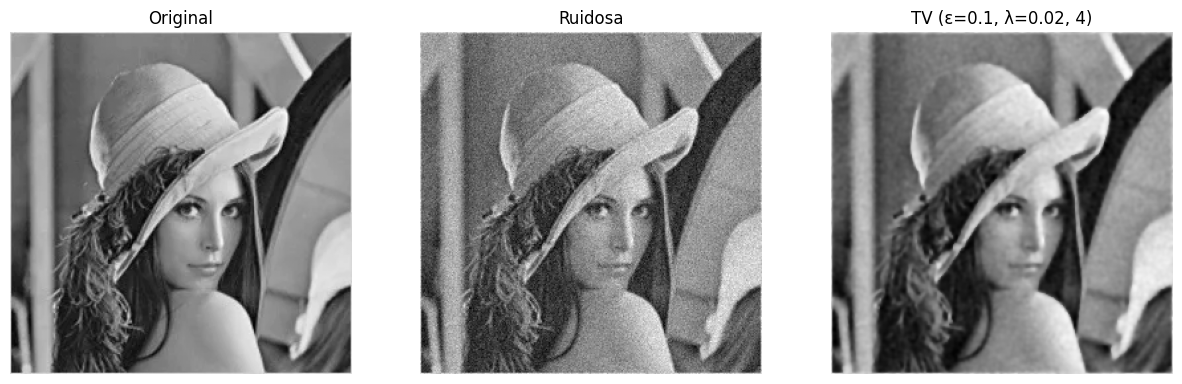

In [118]:
#PRIMERA PRUEBA CON TV PARA LOS COEFICIENTES

sigma=0.05
seed=0
imagen_ruidosa=agregar_ruido_gaussiano(imagen,sigma,seed)

epsilon = 0.1
lamb = 0.02
iteraciones = 4

imagen_filtrada = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": epsilon}, lamb, iteraciones)

plt.figure(figsize=(15, 5))

plt.subplot(1,3,1)
plt.imshow(imagen, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(imagen_ruidosa, cmap='gray')
plt.title('Ruidosa')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(imagen_filtrada, cmap='gray')
plt.title(f'TV (ε={epsilon}, λ={lamb}, {iteraciones})')
plt.axis('off')

plt.show()

In [119]:
#Para calcular el RMSE (sacado de la pregunta 1)
def calculo_rmse(imagen,imagencondenoising):
    rmse=np.sqrt(np.mean((imagen-imagencondenoising)**2))
    return rmse

1. Para el caso TV, explore al menos cuatro valores de ε que cubran un rango suficientemente amplio.
Muestre cómo cambia el mapa cTV y el resultado final. No se limite a indicar que ε evita una división por
cero: analice cómo cambia la difusión en regiones planas, bordes y zonas con textura.

In [120]:
#Defino la función para el calculo del mapa c

def mapa_c(imagen,epsilon):
  gx=np.zeros_like(imagen)
  gy=np.zeros_like(imagen)
  gx[:, 1:-1] = (imagen[:, 2:] - imagen[:, :-2]) / 2.0
  gy[1:-1, :] = (imagen[2:, :] - imagen[:-2, :]) / 2.0
  grad=gx**2+gy**2
  return 1/np.sqrt(grad+epsilon**2)


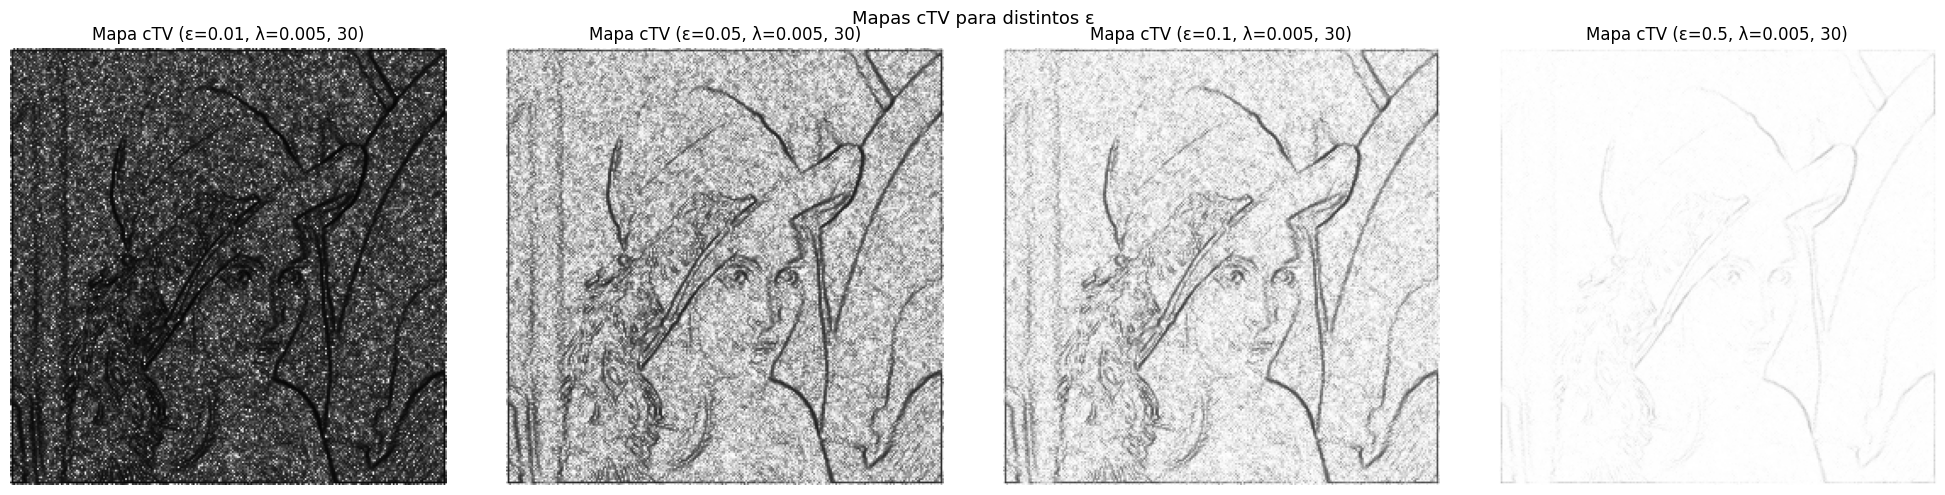

In [121]:
valores_epsilon=[0.01,0.05,0.1,0.5]
lamb=0.005
iteraciones=30

resultados=[]
mapa_c_tv=[]

for eps in valores_epsilon:
  imagen_filtrada = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": eps}, lamb, iteraciones)
  mapa = mapa_c(imagen_ruidosa, eps)
  resultados.append(imagen_filtrada)
  mapa_c_tv.append(mapa)

#Visualización
plt.subplots(1, 4, figsize=(20, 5))

for k, eps in enumerate(valores_epsilon):
    plt.subplot(1, 4, k + 1)
    plt.imshow(mapa_c_tv[k], cmap='gray',vmin=0, vmax=1/eps)
    plt.title(f'Mapa cTV (ε={eps}, λ={lamb}, {iteraciones})')
    plt.axis('off')

plt.suptitle('Mapas cTV para distintos ε', fontsize=13)
plt.tight_layout()
plt.show()



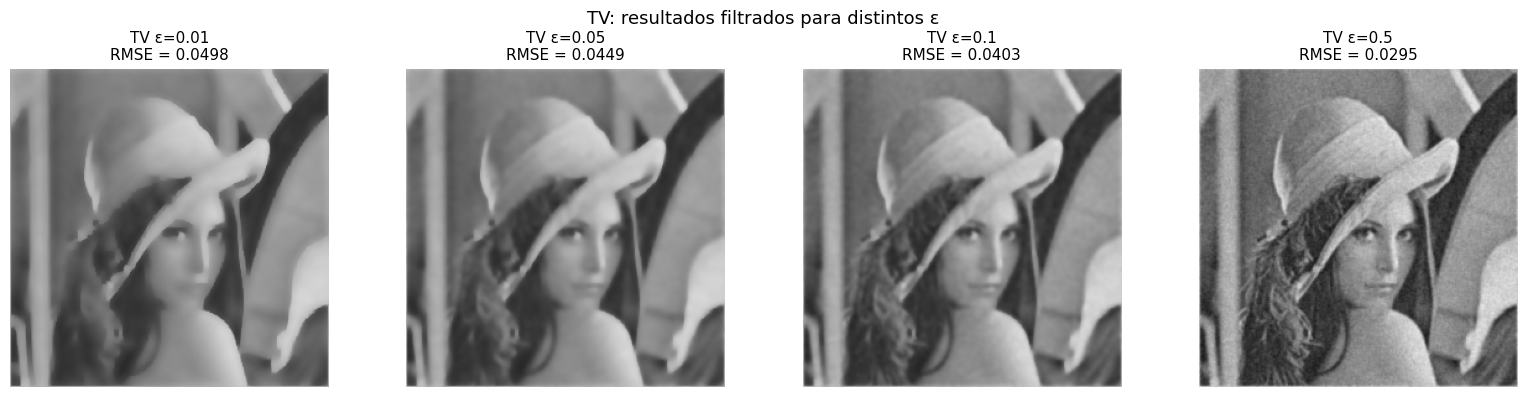

In [141]:
valores_epsilon = [0.01, 0.05, 0.1, 0.5]
lamb = 0.005
iteraciones = 30

resultados = []

for eps in valores_epsilon:
    imagen_filtrada = anisotropica(
        imagen_ruidosa, coeficiente_tv, {"epsilon": eps}, lamb, iteraciones
    )
    resultados.append(imagen_filtrada)

plt.figure(figsize=(16, 4))

for k, eps in enumerate(valores_epsilon):
    plt.subplot(1, 4, k+1)
    plt.imshow(resultados[k], cmap='gray', vmin=0, vmax=1)
    rmse_val = calculo_rmse(imagen, resultados[k])
    plt.title(f'TV ε={eps}\nRMSE = {rmse_val:.4f}', fontsize=11)
    plt.axis('off')

plt.suptitle('TV: resultados filtrados para distintos ε', fontsize=13)
plt.tight_layout()
plt.show()

2. Estudie el efecto conjunto de ε, λ y número de iteraciones. Muestre al menos una situación en la cual una
elección inadecuada produzca una evolución demasiado lenta, un sobre-suavizado o problemas numéricos.

In [122]:
#Evolución demasiado lenta
epsilon1=0.1
lamb1=0.02
iteraciones1=2

filtrada_lenta = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": epsilon1}, lamb1, iteraciones1)


In [123]:
#Sobre-suavizado
epsilon2=0.1
lamb2=0.02
iteraciones2=500

filtrada_sobre_suavizada = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": epsilon2}, lamb2, iteraciones2)

In [124]:
#Problema numérico
epsilon3=0.1
lamb3=0.02
iteraciones3=20
filtrada_inest = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": epsilon3}, lamb3, iteraciones3)

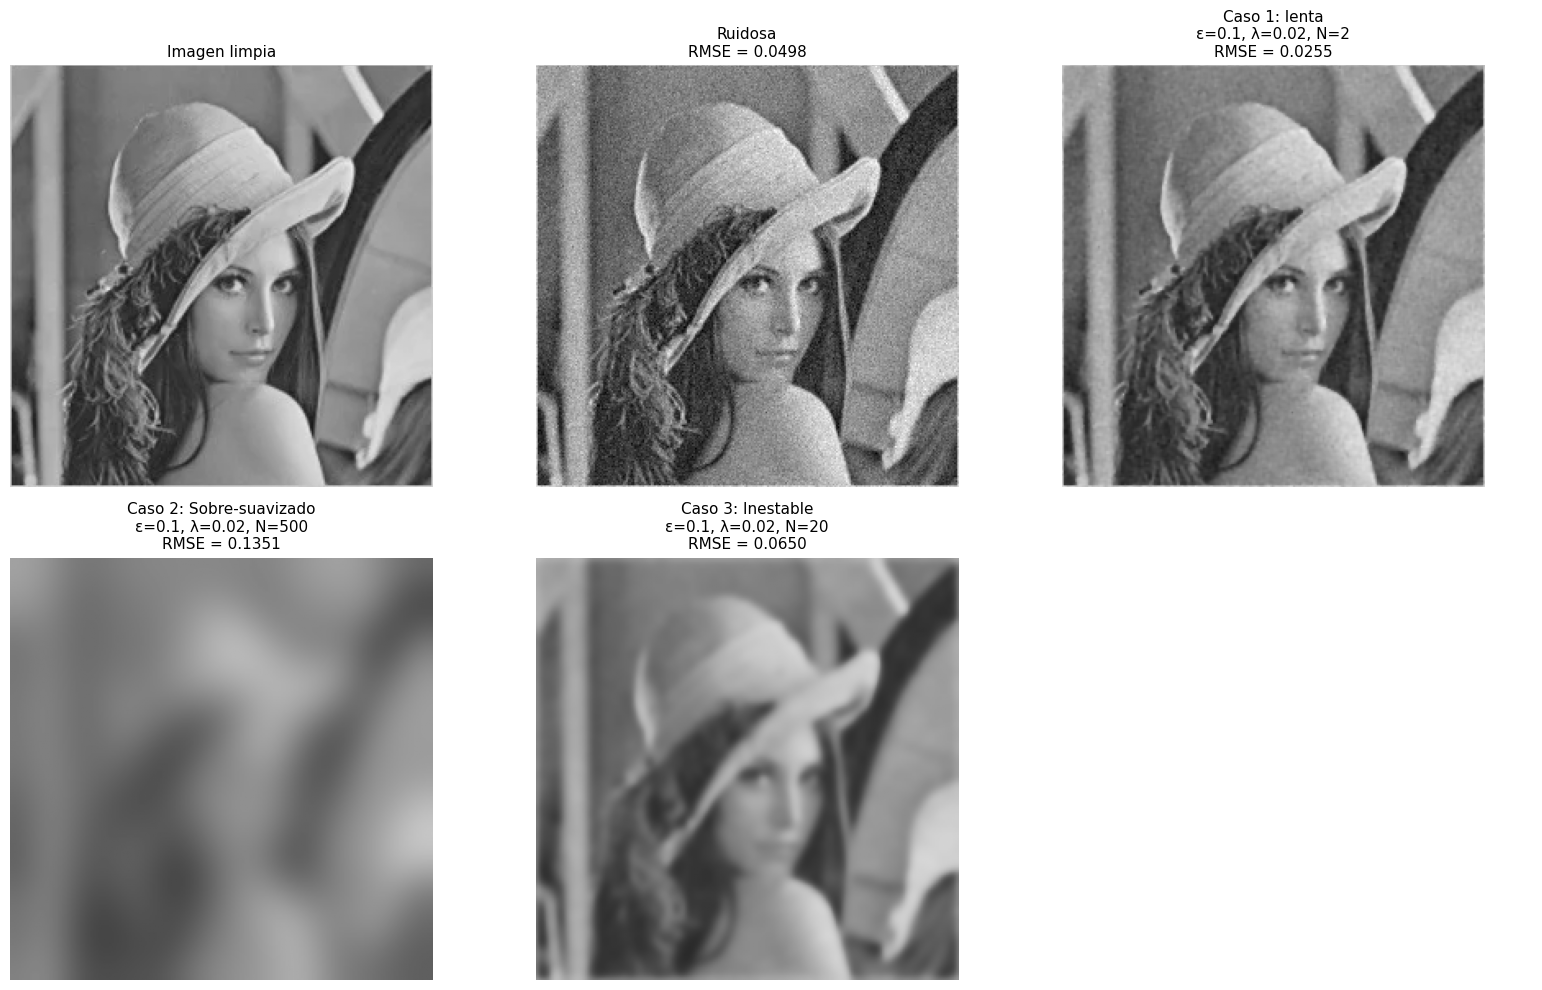

In [125]:
#Imágenes y rmse

rmse_0=calculo_rmse(imagen,imagen_ruidosa)
rmse_1=calculo_rmse(imagen,filtrada_lenta)
rmse_2=calculo_rmse(imagen,filtrada_sobre_suavizada)
rmse_3=calculo_rmse(imagen,filtrada_inest)

plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen limpia', fontsize=11)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(imagen_ruidosa, cmap='gray', vmin=0, vmax=1)
plt.title(f'Ruidosa\nRMSE = {rmse_0:.4f}', fontsize=11)
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(filtrada_lenta, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 1: lenta\n'
          f'ε={epsilon1}, λ={lamb1}, N={iteraciones1}\n'
          f'RMSE = {rmse_1:.4f}', fontsize=11)
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(filtrada_sobre_suavizada, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 2: Sobre-suavizado\n'
          f'ε={epsilon2}, λ={lamb2}, N={iteraciones2}\n'
          f'RMSE = {rmse_2:.4f}', fontsize=11)
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(filtrada_inest, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 3: Inestable\n'
          f'ε={epsilon3}, λ={lamb3}, N={iteraciones3}\n'
          f'RMSE = {rmse_3:.4f}', fontsize=11)
plt.axis('off')

plt.subplot(2, 3, 6).axis('off')

plt.tight_layout()
plt.show()

3. Para cada uno de los dos coeficientes propuestos, explore sus parámetros principales y muestre el mapa c
correspondiente. Explique qué estructuras de la imagen reciben mayor o menor difusión

*   **Coeficiente TV modulado por Laplaciano**
-Parámetros principales: Se introduce el parámetro r, que se encarga de controlar la escala del laplaciano. Si r es pequeño, entonces el ponderador para el laplaciano decae, mientras que si r es grande casi no tiene efecto.

-Efectos en la imagen

*   **Coeficiente Exponencial + Laplaciano**
-Parámetros principales:
Los parámetros utilizados son: r que corresponde a la escala de decaimiento, si r es pequeño significa que decae muy rápido, por otro lado si es grande implica que decae lento (hay mayor difusión) f corresponde al peso que se le da al laplaciano.

In [126]:
#Calculo mapa C

def mapa_c(imagen,h,param):
  gx=np.zeros_like(imagen)
  gy=np.zeros_like(imagen)
  gx[:, 1:-1] = (imagen[:, 2:] - imagen[:, :-2]) / 2.0
  gy[1:-1, :] = (imagen[2:, :] - imagen[:-2, :]) / 2.0
  g=np.sqrt(gx**2 + gy**2)

  lap=np.zeros_like(imagen)
  lap[1:-1, 1:-1] = (imagen[:-2, 1:-1] + imagen[2:, 1:-1] + imagen[1:-1, :-2] + imagen[1:-1, 2:] - 4 * imagen[1:-1, 1:-1])

  return h(g, lap, **param)

In [127]:
#Mapa C correspondiente a coeficiente TV modulado por Laplaciano

filtrada_CTVL = anisotropica(imagen_ruidosa, coeficiente_tv_laplaciano, {"epsilon": 0.1, "r": 0.5}, lamb, iteraciones)

#Mapa C correspondiente a coeficiente Exponencial + Laplaciano

filtrada_CGL = anisotropica(imagen_ruidosa, coeficiente_gradiente_laplac, {"r": 0.1, "f": 1.0}, lamb, iteraciones)

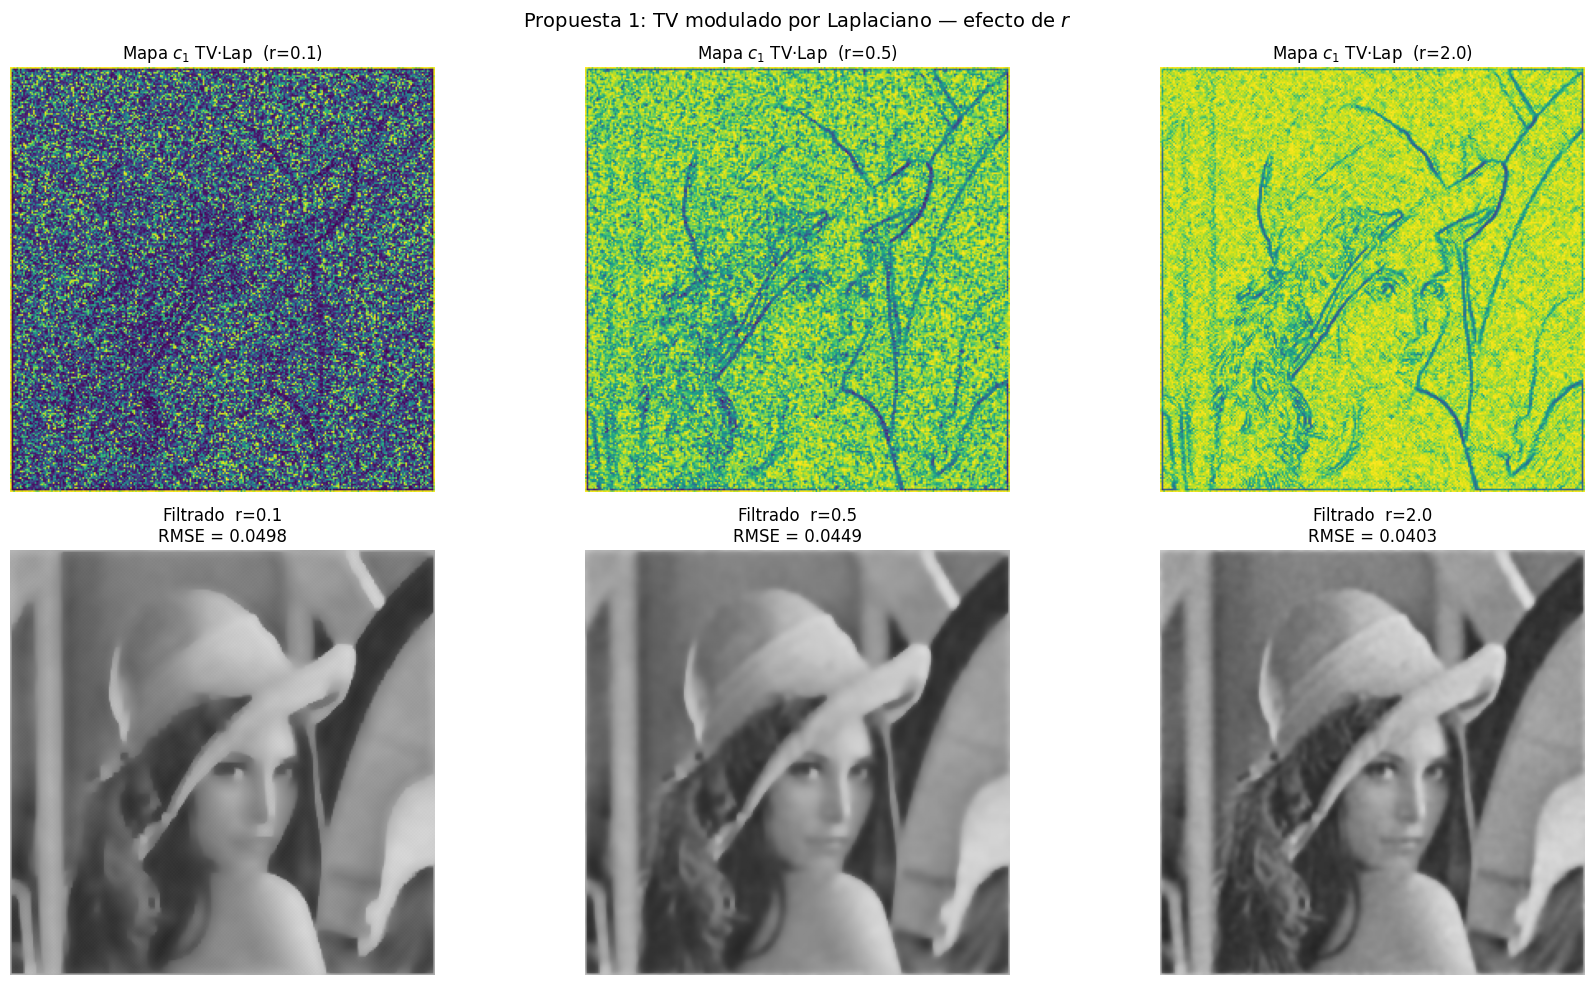

In [128]:
#explorando r
valores_r=[0.1,0.5,2.0]
epsilon=0.1
lamb=0.02
iteraciones=30

resultadosctvl=[]
mapastvl=[]

for r in valores_r:
  filtrada_CTVL = anisotropica(imagen_ruidosa, coeficiente_tv_laplaciano, {"epsilon": 0.1, "r": r}, lamb, iteraciones)
  mapa=mapa_c(imagen_ruidosa, coeficiente_tv_laplaciano, {"epsilon": 0.1, "r": r})
  resultadosctvl.append(filtrada_CTVL)
  mapastvl.append(mapa)

#visualizar
plt.figure(figsize=(18, 10))

for k, r in enumerate(valores_r):
    # Mapa c
    plt.subplot(2, 3, k+1)
    plt.imshow(mapastvl[k], cmap='viridis', vmin=0, vmax=1/epsilon)
    plt.title(rf'Mapa $c_1$ TV·Lap  (r={r})')
    plt.axis('off')

    plt.subplot(2, 3, k+4)
    plt.imshow(resultados[k], cmap='gray', vmin=0, vmax=1)
    rmse_val = calculo_rmse(imagen, resultados[k])
    plt.title(f'Filtrado  r={r}\nRMSE = {rmse_val:.4f}')
    plt.axis('off')

plt.suptitle(r'Propuesta 1: TV modulado por Laplaciano — efecto de $r$', fontsize=14)
plt.tight_layout()
plt.show()


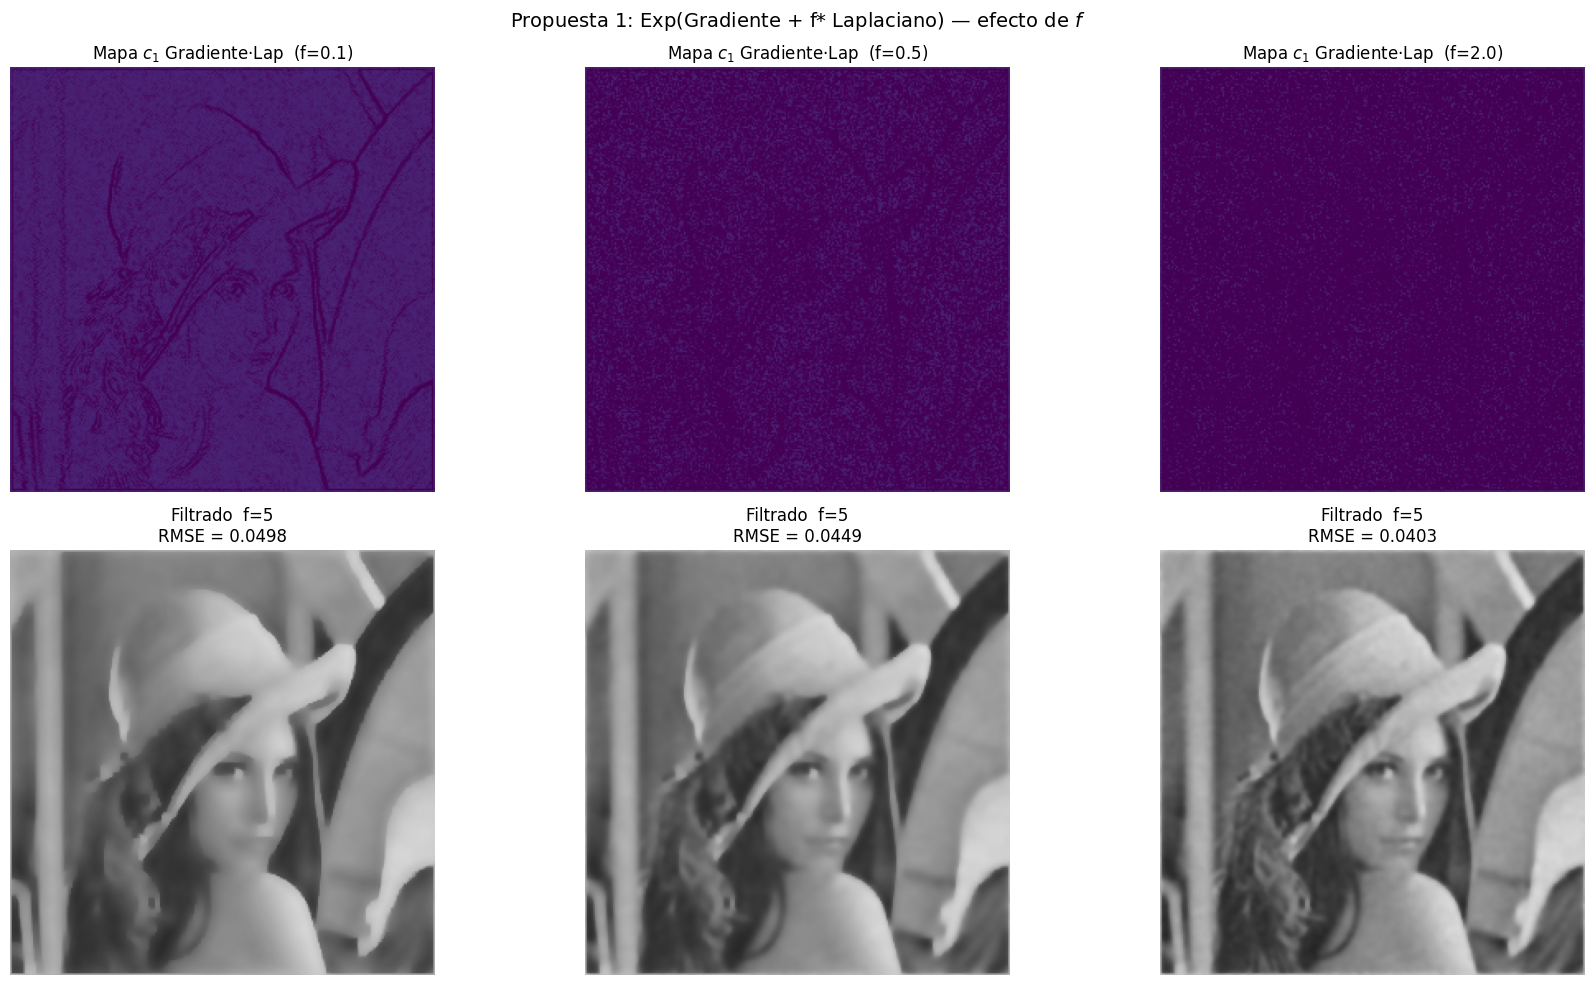

In [129]:
valores_f=[0,1,5]
r_fijo=2
lamb=0.02
iteraciones=30

resultados2=[]
mapacgl=[]

for f in valores_f:
  filtrada_CGL = anisotropica(imagen_ruidosa, coeficiente_gradiente_laplac, {"r": 0.1, "f": f}, lamb, iteraciones)
  mapa2=mapa_c(imagen_ruidosa, coeficiente_gradiente_laplac, {"r": 0.1, "f": f})
  resultados2.append(filtrada_CGL)
  mapacgl.append(mapa2)

#visualizar
plt.figure(figsize=(18, 10))

for k, r in enumerate(valores_r):
    # Mapa c
    plt.subplot(2, 3, k+1)
    plt.imshow(mapacgl[k], cmap='viridis', vmin=0, vmax=1/epsilon)
    plt.title(rf'Mapa $c_1$ Gradiente·Lap  (f={r})')
    plt.axis('off')

    plt.subplot(2, 3, k+4)
    plt.imshow(resultados[k], cmap='gray', vmin=0, vmax=1)
    rmse_val = calculo_rmse(imagen, resultados[k])
    plt.title(f'Filtrado  f={f}\nRMSE = {rmse_val:.4f}')
    plt.axis('off')

plt.suptitle(r'Propuesta 1: Exp(Gradiente + f* Laplaciano) — efecto de $f$', fontsize=14)
plt.tight_layout()
plt.show()

4. En la propuesta que utiliza Laplaciano, analice especialmente la sensibilidad del indicador al ruido. Si
utiliza normalización, suavizado previo, saturación u otro mecanismo para estabilizarlo, describa y evalúe su
efecto.

El laplaciano es un operador que responde a cambios de alta frecuencia, lo que es útil en la detección de texturas, el problema es que también amplifica el ruido blanco.

Esto es porque si el pixel es igual al promedio de sus vecinos, $\Delta$I vale 0, la zona es plana. Si el pixel difiere de este promedio $\Delta$I es grande.

El problema es que el ruido gaussiano hace que cada pixel varie aleatoriamente, por ende la variación no es "real", entonces en una zona plana, el laplaciano estaría detectando valores de tipo borde donde no los hay, dejando de suavizar donde debería.

Mecanismos para estabilizar el ruido:

Modulador: $\Delta$I va elevado al cuadrado, lo que hace que el modulador caiga cuando $\Delta$I es pequeño, pero sature suavemente cuando es grande (amortigua los valores extremos).

Parámetro r grande:
Si r es pequeño, entonces cualquier $\Delta$I reduce c, bloqueando la difusión.

Si tiene valores medios, entonces bloquea la difusión en caso de bordes reales.

Si $\Delta$I es muy grande casi no hay efecto en el modulador.

Entre más grande es r hay menos sensibilidad al ruido.

Peso f:
Si f es 0, no se usa laplaciano y el filtro equivale a un Perona-Malik.

Si vale 1, entonces tanto gradiente como laplaciano pesan lo mismo.

Por último, si f es mucho más grande, el laplaciano domina y vuelve a aparecer bastante ruido.

5. Compare TV y sus dos propuestas utilizando la misma imagen ruidosa. Ajuste razonablemente los
parámetros de cada método y compare reducción de ruido, preservación de bordes, pérdida de textura y
artefactos. Incluya RMSE respecto de la imagen original y al menos un recorte ampliado o perfil que permita
estudiar un borde.

Ruidosa:        RMSE = 0.0498
TV:             RMSE = 0.0854
TV·Laplaciano:  RMSE = 0.0851
Exp grad+lap:   RMSE = 0.0481


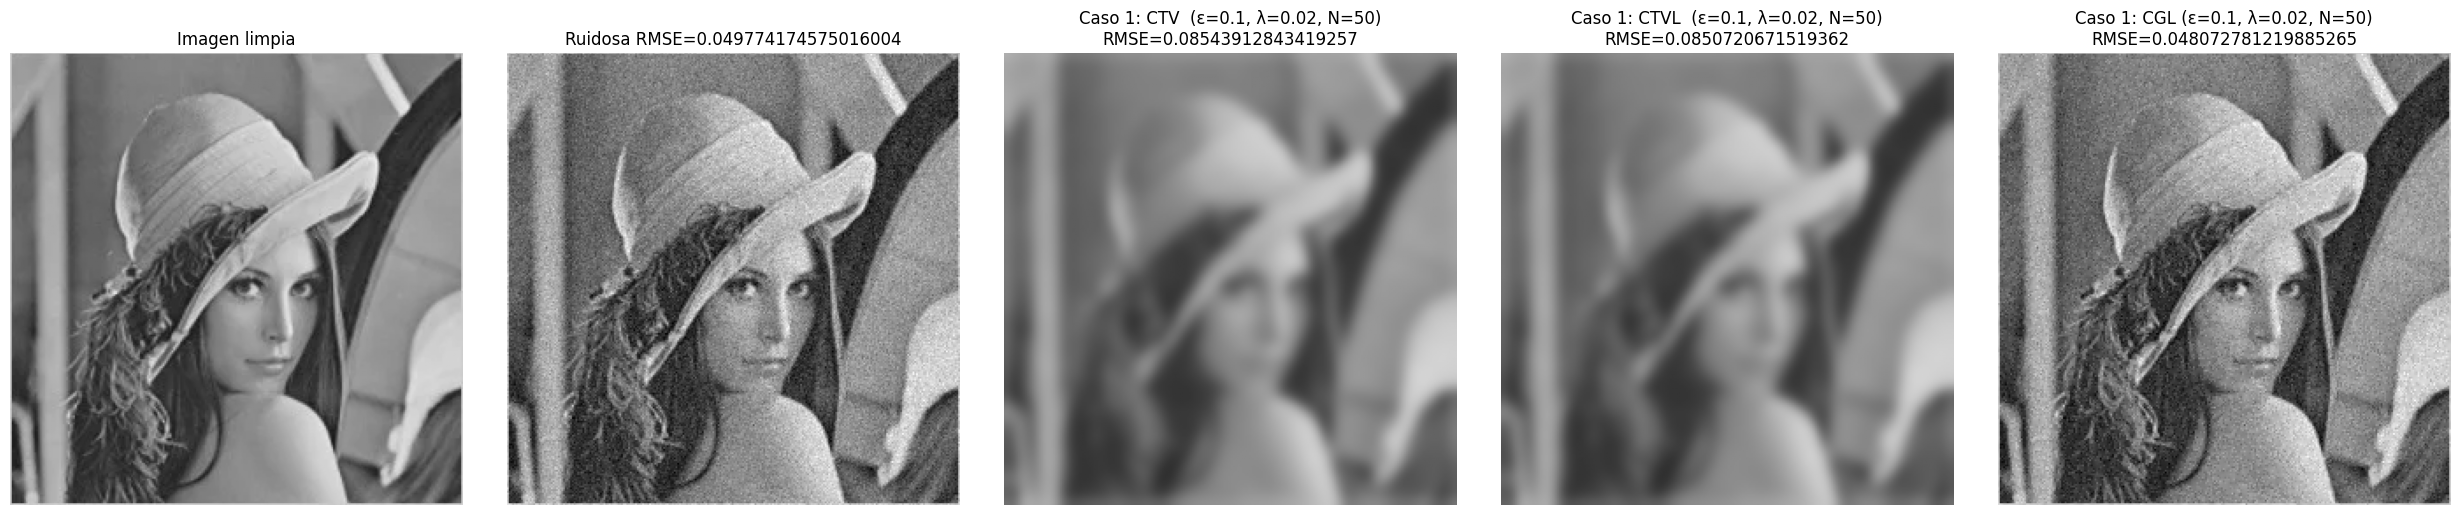

In [142]:
epsilon = 0.1
r_tvlap = 0.5
r_exp   = 0.15
f_exp   = 1.0
lamb = 0.02
iteraciones = 50

#Coeficiente TV
filtrada_CTV = anisotropica(imagen_ruidosa, coeficiente_tv, {"epsilon": 0.1}, lamb, iteraciones)

#Coeficiente TV con laplaciano
filtrada_CTVL = anisotropica(imagen_ruidosa, coeficiente_tv_laplaciano, {"epsilon": 0.1, "r":0.5}, lamb, iteraciones)

#Coeficiente gradiente con laplaciano
filtrada_CGL = anisotropica(imagen_ruidosa, coeficiente_gradiente_laplac, {"r": 0.1, "f": 1.0}, lamb, iteraciones)

#Gráficas
rmse_00=calculo_rmse(imagen,imagen_ruidosa)
rmse_10=calculo_rmse(imagen,filtrada_CTV)
rmse_20=calculo_rmse(imagen,filtrada_CTVL)
rmse_30=calculo_rmse(imagen,filtrada_CGL)

print(f"Ruidosa:        RMSE = {rmse_00:.4f}")
print(f"TV:             RMSE = {rmse_10:.4f}")
print(f"TV·Laplaciano:  RMSE = {rmse_20:.4f}")
print(f"Exp grad+lap:   RMSE = {rmse_30:.4f}")

plt.figure(figsize=(25, 5))

plt.subplot(1, 5, 1)
plt.imshow(imagen, cmap='gray', vmin=0, vmax=1)
plt.title('Imagen limpia')
plt.axis('off')

plt.subplot(1, 5, 2)
plt.imshow(imagen_ruidosa, cmap='gray', vmin=0, vmax=1)
plt.title(f'Ruidosa RMSE={rmse_00}')
plt.axis('off')

plt.subplot(1, 5, 3)
plt.imshow(filtrada_CTV, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 1: CTV  (ε={epsilon}, λ={lamb}, N={iteraciones})\n' f'RMSE={rmse_10}')
plt.axis('off')

plt.subplot(1, 5, 4)
plt.imshow(filtrada_CTVL, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 1: CTVL  (ε={epsilon}, λ={lamb}, N={iteraciones})\n' f'RMSE={rmse_20}')
plt.axis('off')

plt.subplot(1, 5, 5)
plt.imshow(filtrada_CGL, cmap='gray', vmin=0, vmax=1)
plt.title(f'Caso 1: CGL (ε={epsilon}, λ={lamb}, N={iteraciones})\n' f'RMSE={rmse_30}')
plt.axis('off')

plt.tight_layout()
plt.show()

Análisis del recorte de la imágen

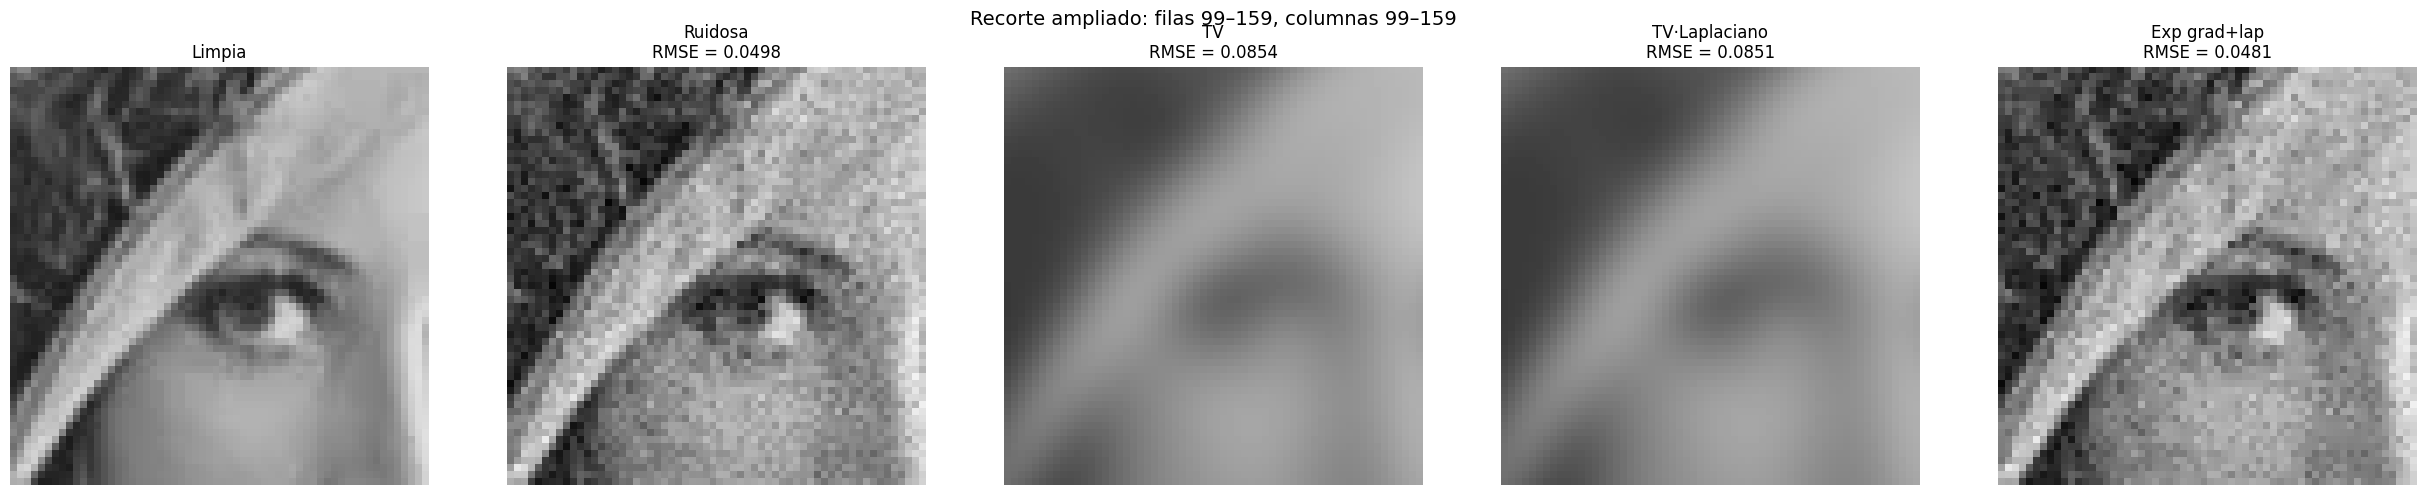

In [143]:
cy_img, cx_img = imagen.shape[0] // 2, imagen.shape[1] // 2
cont=30

fila_i,fila_f= cy_img -cont, cy_img +cont
col_i,col_f= cx_img -cont, cx_img +cont

#recortes
recorte_limpia = imagen[fila_i:fila_f,col_i:col_f]
recorte_ruidosa = imagen_ruidosa[fila_i:fila_f,col_i:col_f]
recorte_ctv = filtrada_CTV[fila_i:fila_f,col_i:col_f]
recorte_ctvl = filtrada_CTVL[fila_i:fila_f,col_i:col_f]
recorte_cgl = filtrada_CGL[fila_i:fila_f,col_i:col_f]

#visualización
plt.figure(figsize=(25, 5))

plt.subplot(1, 5, 1)
plt.imshow(recorte_limpia, cmap='gray', vmin=0, vmax=1)
plt.title('Limpia')
plt.axis('off')

plt.subplot(1, 5, 2)
plt.imshow(recorte_ruidosa, cmap='gray', vmin=0, vmax=1)
plt.title(f'Ruidosa\nRMSE = {rmse_00:.4f}')
plt.axis('off')

plt.subplot(1, 5, 3)
plt.imshow(recorte_ctv, cmap='gray', vmin=0, vmax=1)
plt.title(f'TV\nRMSE = {rmse_10:.4f}')
plt.axis('off')

plt.subplot(1, 5, 4)
plt.imshow(recorte_ctvl, cmap='gray', vmin=0, vmax=1)
plt.title(f'TV·Laplaciano\nRMSE = {rmse_20:.4f}')
plt.axis('off')

plt.subplot(1, 5, 5)
plt.imshow(recorte_cgl, cmap='gray', vmin=0, vmax=1)
plt.title(f'Exp grad+lap\nRMSE = {rmse_30:.4f}')
plt.axis('off')

plt.suptitle(f'Recorte ampliado: filas {fila_i}–{fila_f}, columnas {col_i}–{col_f}', fontsize=14)
plt.tight_layout()
plt.savefig('recorte_ampliado.png', dpi=150, bbox_inches='tight')
plt.show()


6. Identifique al menos una fortaleza y una limitación de cada definición de c. El análisis debe relacionar los
resultados observados con la forma matemática de h(E), no sólo con la apariencia visual final.

1) Coeficiente TV

$$c_{TV}(g) = \frac{1}{\sqrt{g^2 + \epsilon^2}}$$

*   *Fortaleza:* Cuenta con difusión alta en zonas planas (debido a que cuando gradiente es o tiende a 0 el valor de CTV se convierte en $$1/\epsilon$$ .

Por otro si el valor de g es muy grande este domina el denominador,
aproximándose la ecuación a 1/g, tomando CTV un valor mucho más pequeño.

*   *Limitación:* Como se aplica el principio de variación total, se genera staircasing en zonas de gradiente suave.

2) Coeficiente TV modulado por Laplaciano

$$c_1(g, \Delta I) = \frac{1}{\sqrt{g^2 + \epsilon^2}} \cdot \frac{1}{1 + \left(\dfrac{\Delta I}{r}\right)^2}$$

*   *Fortaleza:* El coeficiente es bajo cuando el gradiente es grande, es decir que es bueno preservando bordes.
Cuando el Laplaciano es grande se preservan curvaturas y textura.

*   *Limitación:* El Laplaciano puede amplificar ruido en zonas planas ruiodas.

3) Exponencial + Laplaciano

$$c_2(g, \Delta I) = \exp\!\left(-\frac{g^2 + f(\Delta I)^2}{r^2}\right)$$

En una zona plana g=0  y $ΔI=0$, lo que hace que c=1. Esto implica máxima difusión.

Si tanto g como $ΔI=0$ son grandes, entonces la difusión es mínima.

En partes con textura g es moderado y $ΔI=0$ es grande, asi que según la ecuación se preservaría la textura.

*   *Limitación:* Muy sensible a r, grandes cambios en este parámetro cambia bastante el resultado. Además también tiene el problema del ruido con el laplaciano.